In [1]:
# Install required packages
import subprocess
import sys

def install_package(package):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])
        print(f"Successfully installed {package}")
    except subprocess.CalledProcessError as e:
        print(f"Failed to install {package}: {e}")

# Install packages
packages = ["h2o", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn"]
for package in packages:
    install_package(package)

Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 MB 4.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.2/161.2 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.8/151.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.8/129.8 kB 13.3 MB/s eta 0:00:00
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 43.3 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 40.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# H2O Regression Pipeline for Flight Time Prediction

This notebook implements a regression pipeline using H2O AutoML to predict actual departure and arrival times for flights. Unlike the classification version that predicts delays, this version focuses on predicting the exact timing of flights.

## Key Differences from Classification Pipeline:
- **Target Variables**: Actual departure time (ATD) and actual arrival time (ATA)
- **Problem Type**: Multi-target regression instead of binary classification
- **Evaluation Metrics**: MAE, RMSE, R² instead of AUC, F1-score
- **Business Value**: Precise time predictions for operational planning

In [2]:
# Import required libraries
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="4G")
print("H2O initialized successfully!")

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /home/kristsey/.venv/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpvsrkifh9
  JVM stdout: /tmp/tmpvsrkifh9/h2o_kristsey_started_from_python.out
  JVM stderr: /tmp/tmpvsrkifh9/h2o_kristsey_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,00 secs
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,5 months and 19 days
H2O_cluster_name:,H2O_from_python_kristsey_jmb5ae
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.984 Gb
H2O_cluster_total_cores:,24
H2O_cluster_allowed_cores:,24
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!


In [3]:
# Load the historical flights dataset
print("Loading historical flights dataset...")
data_path = "/home/kristsey/AvinorHackathon/data/historical_flights.csv"

# Load data
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())

Loading historical flights dataset...
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
  flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
0     WF149         HOV            

In [4]:
# Data Preprocessing for Regression
print("Starting data preprocessing for regression...")

# Create a copy for processing
df_processed = df.copy()

# Handle missing values
print(f"Missing values per column:\n{df_processed.isnull().sum()}")

# Convert datetime columns
datetime_cols = ["std", "sta", "atd", "ata"]
for col in datetime_cols:
    if col in df_processed.columns:
        df_processed[col] = pd.to_datetime(df_processed[col], errors="coerce")

# Remove cancelled flights (they don't have actual times)
df_processed = df_processed[df_processed["cancelled"] == 0]
print(f"Dataset shape after removing cancelled flights: {df_processed.shape}")

# Remove rows with missing actual departure or arrival times
df_processed = df_processed.dropna(subset=["atd", "ata"])
print(f"Dataset shape after removing missing actual times: {df_processed.shape}")

# Function to convert datetime to minutes since midnight
def datetime_to_minutes(dt):
    """Convert datetime to minutes since midnight"""
    if pd.isna(dt):
        return None
    return dt.hour * 60 + dt.minute + dt.second / 60

# Create regression targets - convert times to minutes since midnight
print("Converting times to regression targets...")

# Scheduled times as features
df_processed["scheduled_dep_minutes"] = df_processed["std"].apply(datetime_to_minutes)
df_processed["scheduled_arr_minutes"] = df_processed["sta"].apply(datetime_to_minutes)

# Actual times as targets
df_processed["actual_dep_minutes"] = df_processed["atd"].apply(datetime_to_minutes)
df_processed["actual_arr_minutes"] = df_processed["ata"].apply(datetime_to_minutes)

# Calculate scheduled duration
df_processed["scheduled_duration"] = (
    df_processed["scheduled_arr_minutes"] - df_processed["scheduled_dep_minutes"]
)

# Handle negative durations (overnight flights)
df_processed.loc[df_processed["scheduled_duration"] < 0, "scheduled_duration"] += 24 * 60

# Remove rows with invalid target values
df_processed = df_processed.dropna(subset=["actual_dep_minutes", "actual_arr_minutes"])
print(f"Dataset shape after creating regression targets: {df_processed.shape}")

# Display target variable statistics
print(f"\nRegression Target Statistics:")
print(f"Actual Departure Minutes - Mean: {df_processed['actual_dep_minutes'].mean():.1f}, Std: {df_processed['actual_dep_minutes'].std():.1f}")
print(f"Actual Arrival Minutes - Mean: {df_processed['actual_arr_minutes'].mean():.1f}, Std: {df_processed['actual_arr_minutes'].std():.1f}")

Starting data preprocessing for regression...
Missing values per column:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               0
arr_airport_group    178773
service_type            106
std                       0
sta                       0
cancelled                 0
atd                   16115
ata                   16866
dtype: int64
Dataset shape after removing cancelled flights: (399426, 11)
Dataset shape after removing missing actual times: (390856, 11)
Converting times to regression targets...
Dataset shape after creating regression targets: (390856, 16)

Regression Target Statistics:
Actual Departure Minutes - Mean: 770.4, Std: 319.5
Actual Arrival Minutes - Mean: 810.0, Std: 319.8


In [5]:
# Feature Engineering for Regression
print("Starting feature engineering for time prediction...")

# Extract temporal features
df_processed["dep_hour"] = df_processed["std"].dt.hour
df_processed["dep_day_of_week"] = df_processed["std"].dt.dayofweek
df_processed["dep_month"] = df_processed["std"].dt.month
df_processed["dep_day_of_year"] = df_processed["std"].dt.dayofyear

# Circular encoding for time-based features
print("Creating circular encodings for temporal features...")

# Hour of day (0-23) - circular encoding
df_processed["dep_hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["dep_hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)

# Day of week (0-6) - circular encoding
df_processed["dep_day_of_week_sin"] = np.sin(2 * np.pi * df_processed["dep_day_of_week"] / 7)
df_processed["dep_day_of_week_cos"] = np.cos(2 * np.pi * df_processed["dep_day_of_week"] / 7)

# Month (1-12) - circular encoding
df_processed["dep_month_sin"] = np.sin(2 * np.pi * (df_processed["dep_month"] - 1) / 12)
df_processed["dep_month_cos"] = np.cos(2 * np.pi * (df_processed["dep_month"] - 1) / 12)

# Create operational features
df_processed["is_morning_rush"] = ((df_processed["dep_hour"] >= 6) & (df_processed["dep_hour"] <= 9)).astype(int)
df_processed["is_evening_rush"] = ((df_processed["dep_hour"] >= 17) & (df_processed["dep_hour"] <= 20)).astype(int)
df_processed["is_weekend"] = (df_processed["dep_day_of_week"] >= 5).astype(int)

# Create season indicator
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df_processed["season"] = df_processed["dep_month"].apply(get_season)

print("Feature engineering completed!")
print(f"Final processed dataset shape: {df_processed.shape}")

Starting feature engineering for time prediction...
Creating circular encodings for temporal features...
Feature engineering completed!
Final processed dataset shape: (390856, 30)


In [6]:
# Prepare data for H2O Regression
print("Preparing data for H2O regression...")

# Select features for modeling
feature_columns = [
    # Categorical features
    "dep_airport", "arr_airport", "service_type", "season",
    # Primary predictors (scheduled times)
    "scheduled_dep_minutes", "scheduled_arr_minutes", "scheduled_duration",
    # Circular encoded temporal features
    "dep_hour_sin", "dep_hour_cos",
    "dep_day_of_week_sin", "dep_day_of_week_cos",
    "dep_month_sin", "dep_month_cos",
    # Operational features
    "is_morning_rush", "is_evening_rush", "is_weekend"
]

# Regression targets
target_columns = ["actual_dep_minutes", "actual_arr_minutes"]

print(f"Total features selected: {len(feature_columns)}")
print(f"Regression targets: {target_columns}")

# Create modeling dataset
model_data = df_processed[feature_columns + target_columns].copy()

# Remove rows with missing values
model_data = model_data.dropna()
print(f"Modeling dataset shape: {model_data.shape}")

# Convert to H2O Frame
print("Converting to H2O Frame...")
h2o_frame = h2o.H2OFrame(model_data)

# Convert categorical columns to factors
categorical_cols = ["dep_airport", "arr_airport", "service_type", "season"]
for col in categorical_cols:
    if col in h2o_frame.columns:
        h2o_frame[col] = h2o_frame[col].asfactor()

print("H2O Frame created successfully!")
print(f"H2O Frame shape: {h2o_frame.shape}")

Preparing data for H2O regression...
Total features selected: 16
Regression targets: ['actual_dep_minutes', 'actual_arr_minutes']
Modeling dataset shape: (390855, 18)
Converting to H2O Frame...
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
H2O Frame created successfully!
H2O Frame shape: (390855, 18)


In [7]:
# Split data and train regression models
print("Splitting data for regression training...")

# Split into train, validation, and test sets
train, valid, test = h2o_frame.split_frame(ratios=[0.7, 0.15], seed=42)

print(f"Train set shape: {train.shape}")
print(f"Validation set shape: {valid.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and targets
x = feature_columns
y_dep = "actual_dep_minutes"  # First target: actual departure time
y_arr = "actual_arr_minutes"  # Second target: actual arrival time

print(f"Features (x): {len(x)} features")
print(f"Departure target (y_dep): {y_dep}")
print(f"Arrival target (y_arr): {y_arr}")

# Train departure time prediction model
print("\n=== Training Departure Time Prediction Model ===")
aml_departure = H2OAutoML(
    max_models=10,
    max_runtime_secs=600,  # 10 minutes
    seed=42,
    project_name="flight_departure_time_prediction",
    sort_metric="RMSE",
    nfolds=5
)

# Train departure model
print("Training departure time prediction model...")
aml_departure.train(x=x, y=y_dep, training_frame=train, validation_frame=valid)
print(f"Departure model training completed! Leaderboard contains {len(aml_departure.leaderboard)} models")

# Train arrival time prediction model
print("\n=== Training Arrival Time Prediction Model ===")
aml_arrival = H2OAutoML(
    max_models=10,
    max_runtime_secs=600,  # 10 minutes
    seed=42,
    project_name="flight_arrival_time_prediction",
    sort_metric="RMSE",
    nfolds=5
)

# Train arrival model
print("Training arrival time prediction model...")
aml_arrival.train(x=x, y=y_arr, training_frame=train, validation_frame=valid)
print(f"Arrival model training completed! Leaderboard contains {len(aml_arrival.leaderboard)} models")

print("\n=== Both Models Trained Successfully! ===")

Splitting data for regression training...
Train set shape: (273827, 18)
Validation set shape: (58554, 18)
Test set shape: (58474, 18)
Features (x): 16 features
Departure target (y_dep): actual_dep_minutes
Arrival target (y_arr): actual_arr_minutes

=== Training Departure Time Prediction Model ===
Training departure time prediction model...
AutoML progress: |
17:58:13.898: User specified a validation frame with cross-validation still enabled. Please note that the models will still be validated using cross-validation only, the validation frame will be used to provide purely informative validation metrics on the trained models.

███████████████████████████████████████████████████████████████| (done) 100%
Departure model training completed! Leaderboard contains 12 models

=== Training Arrival Time Prediction Model ===
Training arrival time prediction model...
AutoML progress: |
18:01:53.165: User specified a validation frame with cross-validation still enabled. Please note that the models 

In [8]:
# Evaluate Regression Models
print("=== EVALUATING REGRESSION MODELS ===")

# Get best models
best_dep_model = aml_departure.leader
best_arr_model = aml_arrival.leader

print(f"Best departure model: {type(best_dep_model).__name__}")
print(f"Best arrival model: {type(best_arr_model).__name__}")

# Evaluate on test set
print("\n=== DEPARTURE TIME PREDICTION PERFORMANCE ===")
dep_performance = best_dep_model.model_performance(test)
print(f"RMSE: {dep_performance.rmse():.2f} minutes")
print(f"MAE: {dep_performance.mae():.2f} minutes")
print(f"R²: {dep_performance.r2():.4f}")

print("\n=== ARRIVAL TIME PREDICTION PERFORMANCE ===")
arr_performance = best_arr_model.model_performance(test)
print(f"RMSE: {arr_performance.rmse():.2f} minutes")
print(f"MAE: {arr_performance.mae():.2f} minutes")
print(f"R²: {arr_performance.r2():.4f}")

# Display leaderboards
print("\n=== DEPARTURE TIME PREDICTION LEADERBOARD ===")
print(aml_departure.leaderboard.as_data_frame())

print("\n=== ARRIVAL TIME PREDICTION LEADERBOARD ===")
print(aml_arrival.leaderboard.as_data_frame())

# Variable importance
print("\n=== DEPARTURE TIME - VARIABLE IMPORTANCE ===")
dep_varimp = best_dep_model.varimp(use_pandas=True)
print(dep_varimp.head(10))

print("\n=== ARRIVAL TIME - VARIABLE IMPORTANCE ===")
arr_varimp = best_arr_model.varimp(use_pandas=True)
print(arr_varimp.head(10))

=== EVALUATING REGRESSION MODELS ===
Best departure model: H2OStackedEnsembleEstimator
Best arrival model: H2OStackedEnsembleEstimator

=== DEPARTURE TIME PREDICTION PERFORMANCE ===
RMSE: 22.70 minutes
MAE: 10.29 minutes
R²: 0.9949

=== ARRIVAL TIME PREDICTION PERFORMANCE ===
RMSE: 41.29 minutes
MAE: 12.84 minutes
R²: 0.9832

=== DEPARTURE TIME PREDICTION LEADERBOARD ===
                                             model_id       rmse          mse  \
0   StackedEnsemble_AllModels_1_AutoML_1_20250915_...  27.587305   761.059382   
1   StackedEnsemble_BestOfFamily_1_AutoML_1_202509...  27.637940   763.855747   
2                      GBM_1_AutoML_1_20250915_175813  27.720007   768.398790   
3                      GBM_2_AutoML_1_20250915_175813  28.035500   785.989244   
4                      GBM_3_AutoML_1_20250915_175813  28.040884   786.291159   
5                  XGBoost_3_AutoML_1_20250915_175813  28.163414   793.177868   
6                      GBM_4_AutoML_1_20250915_175813  28.1

AttributeError: 'NoneType' object has no attribute 'head'

Creating regression performance visualizations...
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
███████████████████████████████████████████| (done) 100%


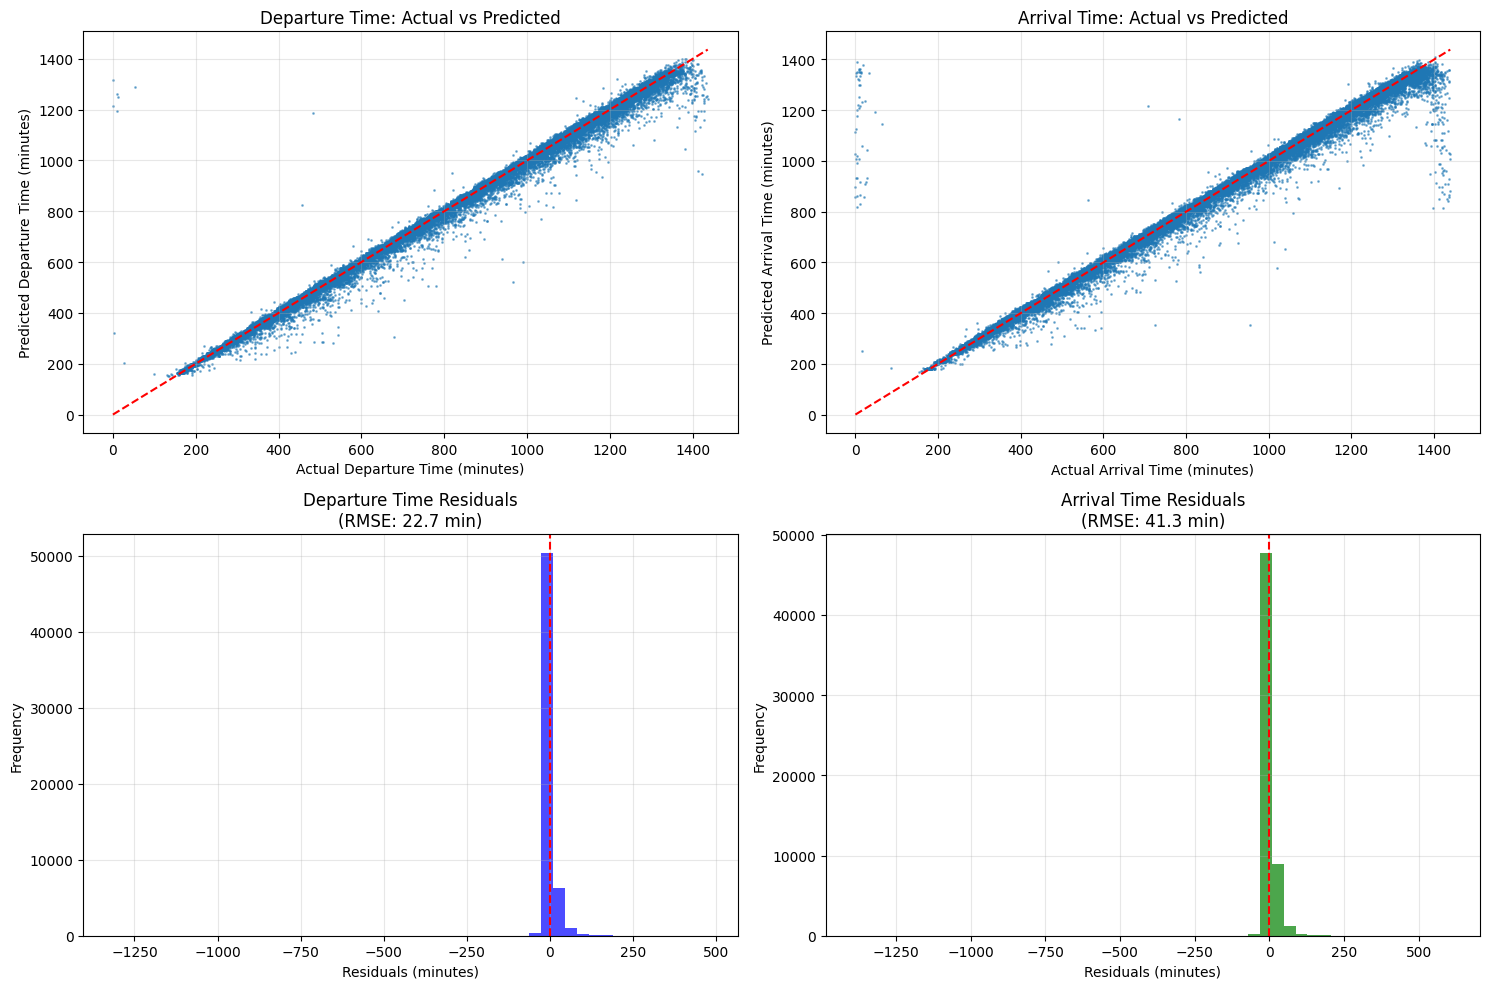


=== REGRESSION PERFORMANCE SUMMARY ===
🛫 DEPARTURE TIME PREDICTION:
   • RMSE: 22.7 minutes (±0.4 hours)
   • MAE: 10.3 minutes
   • R²: 0.995

🛬 ARRIVAL TIME PREDICTION:
   • RMSE: 41.3 minutes (±0.7 hours)
   • MAE: 12.8 minutes
   • R²: 0.983


In [9]:
# Visualize Regression Results
print("Creating regression performance visualizations...")

# Make predictions on test set
dep_predictions = best_dep_model.predict(test)
arr_predictions = best_arr_model.predict(test)

# Convert to pandas for plotting
test_df = test.as_data_frame()
dep_pred_df = dep_predictions.as_data_frame()
arr_pred_df = arr_predictions.as_data_frame()

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Departure Time: Actual vs Predicted
axes[0, 0].scatter(test_df['actual_dep_minutes'], dep_pred_df['predict'], alpha=0.5, s=1)
axes[0, 0].plot([test_df['actual_dep_minutes'].min(), test_df['actual_dep_minutes'].max()], 
                [test_df['actual_dep_minutes'].min(), test_df['actual_dep_minutes'].max()], 'r--')
axes[0, 0].set_xlabel('Actual Departure Time (minutes)')
axes[0, 0].set_ylabel('Predicted Departure Time (minutes)')
axes[0, 0].set_title('Departure Time: Actual vs Predicted')
axes[0, 0].grid(True, alpha=0.3)

# 2. Arrival Time: Actual vs Predicted  
axes[0, 1].scatter(test_df['actual_arr_minutes'], arr_pred_df['predict'], alpha=0.5, s=1)
axes[0, 1].plot([test_df['actual_arr_minutes'].min(), test_df['actual_arr_minutes'].max()],
                [test_df['actual_arr_minutes'].min(), test_df['actual_arr_minutes'].max()], 'r--')
axes[0, 1].set_xlabel('Actual Arrival Time (minutes)')
axes[0, 1].set_ylabel('Predicted Arrival Time (minutes)')
axes[0, 1].set_title('Arrival Time: Actual vs Predicted')
axes[0, 1].grid(True, alpha=0.3)

# 3. Departure Time Residuals
dep_residuals = test_df['actual_dep_minutes'] - dep_pred_df['predict']
axes[1, 0].hist(dep_residuals, bins=50, alpha=0.7, color='blue')
axes[1, 0].set_xlabel('Residuals (minutes)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title(f'Departure Time Residuals\n(RMSE: {dep_performance.rmse():.1f} min)')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].axvline(x=0, color='red', linestyle='--')

# 4. Arrival Time Residuals
arr_residuals = test_df['actual_arr_minutes'] - arr_pred_df['predict']
axes[1, 1].hist(arr_residuals, bins=50, alpha=0.7, color='green')
axes[1, 1].set_xlabel('Residuals (minutes)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title(f'Arrival Time Residuals\n(RMSE: {arr_performance.rmse():.1f} min)')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].axvline(x=0, color='red', linestyle='--')

plt.tight_layout()
plt.show()

# Performance summary
print("\n=== REGRESSION PERFORMANCE SUMMARY ===")
print(f"🛫 DEPARTURE TIME PREDICTION:")
print(f"   • RMSE: {dep_performance.rmse():.1f} minutes (±{dep_performance.rmse()/60:.1f} hours)")
print(f"   • MAE: {dep_performance.mae():.1f} minutes")
print(f"   • R²: {dep_performance.r2():.3f}")

print(f"\n🛬 ARRIVAL TIME PREDICTION:")
print(f"   • RMSE: {arr_performance.rmse():.1f} minutes (±{arr_performance.rmse()/60:.1f} hours)")
print(f"   • MAE: {arr_performance.mae():.1f} minutes")
print(f"   • R²: {arr_performance.r2():.3f}")

In [10]:
# Example Predictions
print("=== EXAMPLE FLIGHT TIME PREDICTIONS ===")

# Function to convert minutes to HH:MM format
def minutes_to_time(minutes):
    if minutes >= 24 * 60:
        minutes = minutes % (24 * 60)  # Handle day rollover
    hours = int(minutes // 60)
    mins = int(minutes % 60)
    return f"{hours:02d}:{mins:02d}"

# Take a sample of test data for examples
sample_size = 10
sample_indices = np.random.choice(test.nrows, sample_size, replace=False)
sample_test = test[sample_indices, :]

# Make predictions on sample
sample_dep_pred = best_dep_model.predict(sample_test)
sample_arr_pred = best_arr_model.predict(sample_test)

# Convert to pandas
sample_df = sample_test.as_data_frame()
sample_dep_pred_df = sample_dep_pred.as_data_frame()
sample_arr_pred_df = sample_arr_pred.as_data_frame()

# Display results
print("\nExample flight time predictions:")
print("="*80)
print(f"{'Route':<10} {'Scheduled':<15} {'Predicted':<15} {'Actual':<15} {'Error':<10}")
print(f"{'':10} {'Dep|Arr':<15} {'Dep|Arr':<15} {'Dep|Arr':<15} {'Dep|Arr':<10}")
print("="*80)

for i in range(len(sample_df)):
    route = f"{sample_df.iloc[i]['dep_airport']}-{sample_df.iloc[i]['arr_airport']}"
    
    # Scheduled times
    sched_dep = minutes_to_time(sample_df.iloc[i]['scheduled_dep_minutes'])
    sched_arr = minutes_to_time(sample_df.iloc[i]['scheduled_arr_minutes'])
    
    # Predicted times
    pred_dep = minutes_to_time(sample_dep_pred_df.iloc[i]['predict'])
    pred_arr = minutes_to_time(sample_arr_pred_df.iloc[i]['predict'])
    
    # Actual times
    actual_dep = minutes_to_time(sample_df.iloc[i]['actual_dep_minutes'])
    actual_arr = minutes_to_time(sample_df.iloc[i]['actual_arr_minutes'])
    
    # Calculate errors
    dep_error = sample_dep_pred_df.iloc[i]['predict'] - sample_df.iloc[i]['actual_dep_minutes']
    arr_error = sample_arr_pred_df.iloc[i]['predict'] - sample_df.iloc[i]['actual_arr_minutes']
    
    print(f"{route:<10} {sched_dep}|{sched_arr:<9} {pred_dep}|{pred_arr:<9} {actual_dep}|{actual_arr:<9} {dep_error:+.0f}|{arr_error:+.0f}")

print("\n💡 BUSINESS APPLICATIONS:")
print("📊 Gate Management: Optimize gate assignments based on predicted times")
print("👥 Passenger Info: Provide more accurate departure/arrival boards")
print("🚛 Ground Services: Schedule baggage, catering, cleaning")
print("✈️ Air Traffic: Better sequencing and slot management")
print("👨‍✈️ Crew Scheduling: Optimize crew assignments and rest periods")

=== EXAMPLE FLIGHT TIME PREDICTIONS ===


H2OResponseError: Server error java.lang.IllegalArgumentException:
  Error: Incorrect number of arguments; 'rows' expects 2 but was passed 3
  Request: POST /99/Rapids
    data: {'ast': '(tmp= py_15_sid_bd99 (rows py_8_sid_bd99 array([53745, 10172, 32404, 20599,  9653, 51665, 44815, 30910, 20471,\n       47964])))', 'session_id': '_sid_bd99'}
